# QMIX on Simple Spread

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kite121/qmix-simple-spread/blob/karimkhab/notebooks/qmix_simple_spread.ipynb)

2 agents · 2 landmarks · one shared reward. Train from scratch → save → reload → play without training.

$$
o_i \;\xrightarrow{\ \text{agent net}\ }\; Q_i(\tau_i,\cdot) \;\xrightarrow{\ \text{mixer}(s),\ W \ge 0\ }\; Q_{tot}(\boldsymbol\tau,\mathbf a,s) \;\xrightarrow{\ \text{TD}\ }\; \mathcal L(\theta)
$$

**Run:** Runtime → Run all (CPU is enough; full training ≈ 5 min on one core). `QUICK_CHECK = True` — smoke test in about a minute.
Inside a local clone of the repository a full run overwrites the seed-0 files in `models/`, `results/`, `configs/`.

## 0. Settings

In [1]:
QUICK_CHECK = False  # True: tiny run (under a minute of training) only to check that every cell works
BRANCH = "karimkhab"  # repository branch with the code; change to "main" after the merge
SEED = 0  # training seed of the main run

## 1. Setup

Clone the code (Colab) and install the environment libraries — same versions as the team [environment notebook](https://colab.research.google.com/drive/1Nn4xIS1bwTzZxao6cly8Br9sOJBBXf_j).

In [2]:
import os
import subprocess
import sys

REPO_URL = "https://github.com/kite121/qmix-simple-spread.git"
if os.path.isdir("../src/qmix_spread"):  # opened inside a clone of the repository
    REPO_DIR = os.path.abspath("..")
else:  # Google Colab: download the code first
    REPO_DIR = os.path.abspath("qmix-simple-spread")
    if not os.path.isdir(REPO_DIR):
        subprocess.run(["git", "clone", "--depth", "1", "--branch", BRANCH, REPO_URL, REPO_DIR], check=True)
sys.path.insert(0, os.path.join(REPO_DIR, "src"))
print("code from:", REPO_DIR)

code from: /Users/Shared/qmix-simple-spread


In [3]:
%pip install -q -r {REPO_DIR}/requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [4]:
import inspect

import numpy as np
import torch
from IPython.display import Code, Image, Markdown, display

from qmix_spread.checkpoint import build_networks, library_versions, load_checkpoint
from qmix_spread.config import QMIXConfig
from qmix_spread.env import ACTION_NAMES, SpreadEnv
from qmix_spread.learner import QMIXLearner, unroll_agent_network
from qmix_spread.networks import AgentNetwork, QMixer
from qmix_spread.plotting import (
    plot_episode_trajectories,
    plot_joint_action_q,
    plot_paired_returns,
    save_episode_gif,
)
from qmix_spread.rollout import QMIXPolicy, RandomPolicy, evaluate, run_episode
from qmix_spread.td_example import (
    check_with_autograd,
    episodes_to_batch,
    format_hand_example,
    format_real_example,
    hand_td_example,
    real_transition_example,
)
from qmix_spread.train import random_baseline, save_run, train

torch.set_num_threads(1)  # tiny networks: one thread is as fast and keeps the run reproducible


def show_source(obj):
    # Shows the code of a class or function from src/qmix_spread right in the notebook.
    display(Code(inspect.getsource(obj), language="python"))


for name, value in library_versions().items():
    print(f"{name:>10}: {value}")

    python: 3.13.13
     torch: 2.14.1
     numpy: 2.5.3
      mpe2: 1.1.1
pettingzoo: 1.27.0
 gymnasium: 1.3.0


## 2. Simple Spread

`simple_spread_v3.parallel_env(N=2, local_ratio=0, max_cycles=25, continuous_actions=False)` from `mpe2 1.1.1` — identical to the [environment notebook](https://colab.research.google.com/drive/1Nn4xIS1bwTzZxao6cly8Br9sOJBBXf_j) (checked by `test_environment_matches_teammate_notebook`).

$$
\begin{aligned}
a_i &\in \{\text{no-op},\ \leftarrow,\ \rightarrow,\ \downarrow,\ \uparrow\} \\
o_i &= \big[\,v_i,\ p_i,\ \ell_1 - p_i,\ \ell_2 - p_i,\ p_j - p_i,\ c_j\,\big] \in \mathbb R^{12} \\
s &= [\,o_1,\ o_2\,] \in \mathbb R^{24} \\
r_t &= -\textstyle\sum_{k=1}^{2} \min_{i} \lVert p_i - \ell_k \rVert
\end{aligned}
$$

$v$ velocity, $p$ position, $\ell_k$ landmark, $c$ communication (always 0). One reward for the team, no collision penalty.

In [5]:
config = QMIXConfig(seed=SEED)
if QUICK_CHECK:
    config.total_env_steps = 5_000
    config.eval_interval_steps = 2_500

env = SpreadEnv(config)
print(f"agents: {env.n_agents}, actions per agent: {env.n_actions} {ACTION_NAMES}")
print(f"observation of one agent: {env.obs_dim} numbers, full state: {env.state_dim} numbers")

obs, state = env.reset(seed=30_000)  # seed fixes the start positions
parts = [("own velocity", 0, 2), ("own position", 2, 4), ("landmark 1, relative", 4, 6),
         ("landmark 2, relative", 6, 8), ("other agent, relative", 8, 10), ("communication (unused)", 10, 12)]
for i in range(env.n_agents):
    print(f"\nagent {i + 1} observation:")
    for label, start, end in parts:
        print(f"  {label:<24} {obs[i, start:end].round(3)}")
print("\nfull state == both observations one after another:", np.allclose(state, obs.reshape(-1)))

# One step: agent 1 goes up, agent 2 goes left. SpreadEnv.step checks that both rewards are equal.
next_obs, next_state, reward, terminated, truncated = env.step(np.array([4, 1]))
print(f"after one step: team reward {reward:.4f}, terminated={terminated}, truncated={truncated}")

agents: 2, actions per agent: 5 ['no_action', 'move_left', 'move_right', 'move_down', 'move_up']
observation of one agent: 12 numbers, full state: 24 numbers

agent 1 observation:
  own velocity             [0. 0.]
  own position             [-0.399  0.231]
  landmark 1, relative     [-0.256 -0.44 ]
  landmark 2, relative     [ 0.655 -0.628]
  other agent, relative    [-0.369 -0.446]
  communication (unused)   [0. 0.]

agent 2 observation:
  own velocity             [0. 0.]
  own position             [-0.768 -0.215]
  landmark 1, relative     [0.113 0.006]
  landmark 2, relative     [ 1.024 -0.182]
  other agent, relative    [0.369 0.446]
  communication (unused)   [0. 0.]

full state == both observations one after another: True
after one step: team reward -1.0203, terminated=False, truncated=False


## 3. QMIX in three lines

$$
Q_i(\tau_i, a) = f_\theta\big(o_i^t,\ a_i^{t-1},\ i,\ h_i^{t-1}\big) \qquad \text{one network shared by both agents}
$$

$$
Q_{tot}(\boldsymbol\tau, \mathbf a, s) = g_\phi\big(Q_1(\tau_1, a_1),\ Q_2(\tau_2, a_2);\ s\big), \qquad \frac{\partial Q_{tot}}{\partial Q_i} \ge 0
$$

$$
\Longrightarrow\quad \arg\max_{\mathbf a} Q_{tot} = \Big(\arg\max_{a_1} Q_1,\ \arg\max_{a_2} Q_2\Big)
$$

| | training | execution |
| --- | :---: | :---: |
| agent net → $Q_i$ | ✓ | ✓ |
| mixer → $Q_{tot}$, full state $s$ | ✓ | – |
| target networks $\theta^-$ | ✓ | – |

## 4. Agent network → $Q_i$

$$
\begin{aligned}
x_i^t &= \big[\,o_i^t\ \|\ \mathrm{onehot}(a_i^{t-1})\ \|\ \mathrm{onehot}(i)\,\big] \in \mathbb R^{12 + 5 + 2} \\
h_i^t &= \mathrm{GRU}\big(\mathrm{ReLU}(W_{in}\, x_i^t),\ h_i^{t-1}\big) \in \mathbb R^{64} \\
Q_i(\tau_i, \cdot) &= W_{out}\, h_i^t \in \mathbb R^{5}
\end{aligned}
$$

In [6]:
show_source(AgentNetwork.forward)

def forward(
        self, obs: torch.Tensor, last_actions_onehot: torch.Tensor, hidden: torch.Tensor
    ) -> tuple[torch.Tensor, torch.Tensor]:
        """One time step for all agents at once.

        obs                 [B, n, O]
        last_actions_onehot [B, n, A]  (all zeros at the first step of an episode)
        hidden              [B, n, H]
        returns q [B, n, A] and the new hidden [B, n, H]
        """
        batch_size = obs.shape[0]

        # One-hot agent ids, the same for every episode in the batch.
        # torch.eye(2) = [[1, 0],      agent 0
        #                 [0, 1]]      agent 1
        # .expand(B, -1, -1) repeats this [n, n] matrix B times without copying memory -> [B, n, n]
        agent_ids = torch.eye(self.n_agents).expand(batch_size, -1, -1)

        # Glue the three parts along the last axis: [B, n, O + A + n]
        inputs = torch.cat([obs, last_actions_onehot, agent_ids], dim=-1)

        # Weights are shared, so every (episode, agent) pair is just one more row.
        # reshape [B, n, 19] -> [B*n, 19]; e.g. B=3, n=2 gives 6 rows:
        #   row 0 = episode 0 agent 0, row 1 = episode 0 agent 1, row 2 = episode 1 agent 0, ...
        x = inputs.reshape(batch_size * self.n_agents, -1)
        h = hidden.reshape(batch_size * self.n_agents, self.hidden_dim)

        x = F.relu(self.fc_in(x))  # [B*n, H]
        h = self.gru(x, h)  # [B*n, H]  memory updated with the current input
        q = self.fc_out(h)  # [B*n, A]  <- the individual Q_i values

        # Back to one row per episode and one slot per agent.
        return q.view(batch_size, self.n_agents, self.n_actions), h.view(
            batch_size, self.n_agents, self.hidden_dim
        )

In [7]:
torch.manual_seed(SEED)
agent_net, mixer = build_networks(config, env)  # untrained: random weights

obs, state = env.reset(seed=30_000)
obs_t = torch.as_tensor(obs).unsqueeze(0)  # [1, n, O] = [1, 2, 12]
no_last_action = torch.zeros(1, env.n_agents, env.n_actions)  # first step: no previous action
q, hidden = agent_net(obs_t, no_last_action, agent_net.init_hidden(1))
print("input:", tuple(obs_t.shape), "+", tuple(no_last_action.shape), " ->  Q:", tuple(q.shape), " memory:", tuple(hidden.shape))
for i in range(env.n_agents):
    values = ", ".join(f"{name} {v:+.3f}" for name, v in zip(ACTION_NAMES, q[0, i].tolist()))
    print(f"Q_{i + 1}: {values}")
print("(the network is not trained yet, so the values are small and mean nothing)")

input: (1, 2, 12) + (1, 2, 5)  ->  Q: (1, 2, 5)  memory: (1, 2, 64)
Q_1: no_action -0.030, move_left +0.046, move_right -0.010, move_down +0.004, move_up -0.176
Q_2: no_action -0.028, move_left -0.001, move_right -0.034, move_down -0.007, move_up -0.156
(the network is not trained yet, so the values are small and mean nothing)


## 5. Mixer → $Q_{tot}$

$$
\begin{aligned}
\tilde s &= 3 \tanh(s / 3) \\
W_1 &= \lvert \mathrm{hyper}_{1}(\tilde s) \rvert \in \mathbb R^{2 \times 32}, \quad b_1 = \mathrm{hyper}_{b_1}(\tilde s) \\
W_2 &= \lvert \mathrm{hyper}_{2}(\tilde s) \rvert \in \mathbb R^{32 \times 1}, \quad b_2 = V(\tilde s) \\
Q_{tot} &= \mathrm{ELU}\big(\mathbf Q\, W_1 + b_1\big)\, W_2 + b_2, \qquad \mathbf Q = (Q_1, Q_2)
\end{aligned}
$$

$W \ge 0$ and ELU is increasing $\Rightarrow \partial Q_{tot} / \partial Q_i \ge 0$. $\tilde s$ is our addition (not in the paper): a soft limit for rare large state values (report, 6.3).

In [8]:
show_source(QMixer.forward)

def forward(self, agent_qs: torch.Tensor, states: torch.Tensor) -> torch.Tensor:
        """agent_qs [..., n] (one chosen Q_i per agent), states [..., S]  ->  Q_tot [...].

        Any leading shape works, e.g. [B, T] for a batch of whole episodes.
        """
        leading_shape = agent_qs.shape[:-1]
        qs = agent_qs.reshape(-1, 1, self.n_agents)  # [N, 1, n]  N = all leading dims flattened
        s = states.reshape(-1, self.state_dim)  # [N, S]

        # Not in the paper: soft limit of the state values, limit * tanh(s / limit). With limit = 3:
        #   0.5 -> 0.50,  1.0 -> 0.96,  2.0 -> 1.75,  4.5 -> 2.71,  50.0 -> 3.00
        # Most state values lie within +-1.5 and are almost unchanged. Values up to about 4.5
        # (agents far from the start area at the end of an episode) are rare in the data; the
        # hypernetworks are linear in s and extrapolated badly there, so Q_tot for such states
        # grew far too large in our pilot runs (see the report). The limit compresses these tails.
        if self.state_limit is not None:
            s = self.state_limit * torch.tanh(s / self.state_limit)

        # First layer weights, generated from the state and made non-negative.
        w1 = torch.abs(self.hyper_w1(s)).view(-1, self.n_agents, self.embed_dim)  # [N, n, E]
        b1 = self.hyper_b1(s).view(-1, 1, self.embed_dim)  # [N, 1, E]

        # torch.bmm = one matrix product per row of the batch: [N, 1, n] x [N, n, E] -> [N, 1, E]
        # Example for one row with n=2, E=3:
        #   qs = [[2.0, 1.0]]   w1 = [[0.5, 0.1, 0.0],
        #                             [0.2, 0.3, 1.0]]
        #   qs @ w1 = [[2*0.5 + 1*0.2, 2*0.1 + 1*0.3, 2*0.0 + 1*1.0]] = [[1.2, 0.5, 1.0]]
        # Each hidden unit is a weighted sum of the agents' Q values with non-negative weights.
        hidden = F.elu(torch.bmm(qs, w1) + b1)  # [N, 1, E]

        # Second layer: E hidden units -> one number.
        w2 = torch.abs(self.hyper_w2(s)).view(-1, self.embed_dim, 1)  # [N, E, 1]
        b2 = self.hyper_b2(s).view(-1, 1, 1)  # [N, 1, 1]
        q_tot = torch.bmm(hidden, w2) + b2  # [N, 1, E] x [N, E, 1] -> [N, 1, 1]

        return q_tot.view(leading_shape)

In [9]:
best_q = q[0].max(dim=1).values.unsqueeze(0)  # [1, n]: Q of each agent's best action
state_t = torch.as_tensor(state).unsqueeze(0)  # [1, S] = [1, 24]
q_tot = mixer(best_q, state_t)
w1 = torch.abs(mixer.hyper_w1(state_t)).view(env.n_agents, config.mixing_embed_dim)
w2 = torch.abs(mixer.hyper_w2(state_t)).view(config.mixing_embed_dim, 1)
print(f"Q_1, Q_2 = {best_q[0].tolist()}  ->  Q_tot = {q_tot.item():.4f}")
print(f"W1: shape {tuple(w1.shape)}, smallest entry {w1.min():.4f} (never negative)")
print(f"W2: shape {tuple(w2.shape)}, smallest entry {w2.min():.4f} (never negative)")

# Monotonicity checked with numbers: dQ_tot/dQ_i >= 0 on 1000 random inputs.
random_qs = (torch.randn(1000, env.n_agents) * 20).requires_grad_(True)
random_states = torch.randn(1000, env.state_dim) * 2
mixer(random_qs, random_states).sum().backward()
print(f"smallest dQ_tot/dQ_i over 1000 random inputs: {random_qs.grad.min():.2e}  (>= 0)")

Q_1, Q_2 = [0.045638687908649445, -0.0011850520968437195]  ->  Q_tot = -0.0028
W1: shape (2, 32), smallest entry 0.0012 (never negative)
W2: shape (32, 1), smallest entry 0.0162 (never negative)
smallest dQ_tot/dQ_i over 1000 random inputs: 2.50e-10  (>= 0)


**Why each agent can act alone:** $Q_{tot}$ for all $5 \times 5$ joint actions (untrained mixer — holds for any weights). Framed cell = best joint action.

best joint action: ['move_left', 'move_left'] | each agent's own best: ['move_left', 'move_left'] | same: True


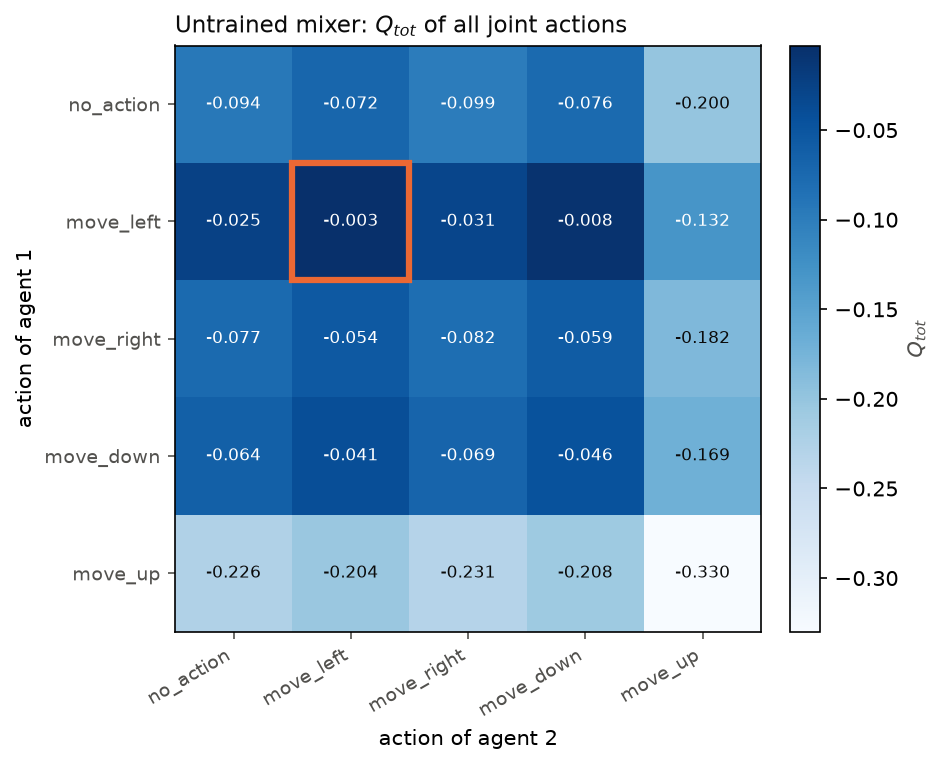

In [10]:
def joint_action_q(agent_q, mixer, state_t):
    # agent_q [n, A] for n = 2 agents -> Q_tot [A, A] for every joint action (row: agent 1, column: agent 2).
    a1, a2 = torch.meshgrid(torch.arange(env.n_actions), torch.arange(env.n_actions), indexing="ij")
    pairs = torch.stack([agent_q[0, a1.flatten()], agent_q[1, a2.flatten()]], dim=1)  # [A*A, 2]
    with torch.no_grad():
        q_tot = mixer(pairs, state_t.expand(len(pairs), -1))  # [A*A]
    return q_tot.view(env.n_actions, env.n_actions).numpy()


table = joint_action_q(q[0].detach(), mixer, state_t)
best_joint = np.unravel_index(table.argmax(), table.shape)
best_individual = tuple(int(a) for a in q[0].argmax(dim=1))
plot_joint_action_q(table, ACTION_NAMES, "Untrained mixer: $Q_{tot}$ of all joint actions");
print("best joint action:", [ACTION_NAMES[a] for a in best_joint],
      "| each agent's own best:", [ACTION_NAMES[a] for a in best_individual],
      "| same:", tuple(int(a) for a in best_joint) == best_individual)

## 6. TD target and loss

$$
\begin{aligned}
\hat a_i' &= \arg\max_a Q_i(\tau_i', a;\ \theta) \\
y_t &= r_t + \gamma\, Q_{tot}\big(\boldsymbol\tau', \hat{\mathbf a}', s_{t+1};\ \theta^-\big) \\
\delta_t &= y_t - Q_{tot}\big(\boldsymbol\tau, \mathbf a_t, s_t;\ \theta\big) \\
\mathcal L(\theta) &= \frac{1}{B\,T} \sum_{b=1}^{B} \sum_{t=1}^{T} \delta_{b,t}^2
\end{aligned}
$$

Online net $\theta$ picks $\hat{\mathbf a}'$, target nets $\theta^-$ rate it (Double Q); $\theta^- \leftarrow \theta$ every 200 episodes. $B = 32$ episodes, $T = 25$ steps, $\gamma = 0.95$ (paper: 0.99, diverged here — report, 6.3). The 25-step limit is a time-out, not a terminal state, so $y_t$ always keeps $\gamma\, Q_{tot}$.

In [11]:
show_source(QMIXLearner.compute_td_loss)

def compute_td_loss(self, batch: dict[str, torch.Tensor]) -> tuple[torch.Tensor, dict[str, torch.Tensor]]:
        """Squared TD error of Q_tot, averaged over all episodes and steps of the batch.

        Batch (from EpisodeBuffer.sample): obs [B, T+1, n, O], state [B, T+1, S],
        actions [B, T, n], reward [B, T], terminated [B, T].
        Returns the loss and the intermediate tensors (used by the numeric example).
        """
        obs, state, actions = batch["obs"], batch["state"], batch["actions"]
        reward, terminated = batch["reward"], batch["terminated"]

        # 1) Individual Q_i of every agent, for every action, at every step.
        q_all = unroll_agent_network(self.agent_net, obs, actions)  # [B, T+1, n, A]

        # Keep only the Q value of the action each agent actually took at steps 0..T-1.
        # gather picks, along the action axis (dim 3), the entry whose index is in `actions`:
        #   Q of one agent at one step = [0.1, 0.7, -0.2, 0.0, 0.3], action taken = 1  ->  0.7
        # actions.unsqueeze(-1) adds the axis gather needs: [B, T, n] -> [B, T, n, 1].
        chosen_q = torch.gather(q_all[:, :-1], dim=3, index=actions.unsqueeze(-1)).squeeze(-1)  # [B, T, n]

        # 2) Mix the agents' chosen Q_i into the team value Q_tot, using the full state.
        q_tot = self.mixer(chosen_q, state[:, :-1])  # [B, T]

        # 3) TD target y = r + gamma * Q_tot_target(next step, best joint action).
        with torch.no_grad():  # the target is a fixed number for this step, no gradient through it
            target_q_all = unroll_agent_network(self.target_agent_net, obs, actions)  # [B, T+1, n, A]
            # Value of every agent's best action at the next step (steps 1..T).
            # Because the mixer is monotonic, "every agent takes its own best action" gives the
            # best joint action for Q_tot as well, so we never need to try all 5 x 5 combinations.
            if self.double_q:
                # Double Q-learning: the online network picks the action, the target network rates it.
                # A single network that both picks and rates the max tends to overestimate.
                next_actions = q_all[:, 1:].argmax(dim=3, keepdim=True)  # [B, T, n, 1]
                target_max_q = torch.gather(target_q_all[:, 1:], dim=3, index=next_actions).squeeze(3)  # [B, T, n]
            else:
                target_max_q = target_q_all[:, 1:].max(dim=3).values  # [B, T, n]
            target_q_tot = self.target_mixer(target_max_q, state[:, 1:])  # [B, T]
            # (1 - terminated) drops the future only if the task itself ended. The 25-step time
            # limit is not such an end: the task does not depend on time and the state has no
            # step counter, so we still bootstrap from the next state, as pymarl does
            # (Pardo et al., 2018, "Time Limits in Reinforcement Learning").
            td_target = reward + self.gamma * (1.0 - terminated) * target_q_tot  # [B, T]

        # 4) TD error and the loss that is minimised: mean of squared TD errors.
        td_error = td_target - q_tot  # [B, T]  > 0 means "better than the network expected"
        loss = (td_error**2).mean()

        details = {
            "q_all": q_all,
            "chosen_q": chosen_q,
            "q_tot": q_tot,
            "target_max_q": target_max_q,
            "target_q_tot": target_q_tot,
            "td_target": td_target,
            "td_error": td_error,
        }
        return loss, details

In [12]:
rng = np.random.default_rng(0)
random_agents = RandomPolicy(env.n_agents, env.n_actions)
episodes = [run_episode(env, random_agents, seed=40_000 + k, rng=rng) for k in range(4)]
batch = episodes_to_batch(episodes)
learner = QMIXLearner(agent_net, mixer, config)
loss, details = learner.compute_td_loss(batch)

print("batch (B episodes, T = 25 steps, n = 2 agents):")
for key, value in batch.items():
    print(f"  {key:<11} {tuple(value.shape)}")
print("intermediate tensors:")
for key, value in details.items():
    print(f"  {key:<14} {tuple(value.shape)}")
print(f"loss = mean(td_error ** 2) = {loss.item():.4f}")

batch (B episodes, T = 25 steps, n = 2 agents):
  obs         (4, 26, 2, 12)
  state       (4, 26, 24)
  actions     (4, 25, 2)
  reward      (4, 25)
  terminated  (4, 25)
intermediate tensors:
  q_all          (4, 26, 2, 5)
  chosen_q       (4, 25, 2)
  q_tot          (4, 25)
  target_max_q   (4, 25, 2)
  target_q_tot   (4, 25)
  td_target      (4, 25)
  td_error       (4, 25)
loss = mean(td_error ** 2) = 2.4277


## 7. One TD update by hand

One-layer mixer $Q_{tot} = w_1 Q_1 + w_2 Q_2 + b$, so every number can be checked on paper. $\eta = 0.005$ is large on purpose (training: $5 \cdot 10^{-4}$).

In [13]:
example = hand_td_example()
display(Markdown(format_hand_example(example)))
autograd = check_with_autograd(example)
print(f"PyTorch autograd recomputed every number; largest difference: {autograd['max_abs_difference']:.2e}")

$$
\begin{aligned}
\text{given:}\quad & r = -1,\ \gamma = 0.95,\ \eta = 0.005 \\
& (Q_1, Q_2) = (-4, -6),\ (w_1, w_2, b) = (0.5, 1, -2) \\
Q_{tot} &= w_1 Q_1 + w_2 Q_2 + b = 0.5 \cdot (-4) + 1 \cdot (-6) + (-2) = -10 \\
Q_1(\tau_1', \cdot) &= \big(-6,\ -5.5,\ \mathbf{-5},\ -7,\ -6.5\big)\quad \text{(max in bold)} \\
Q_2(\tau_2', \cdot) &= \big(-3,\ \mathbf{-2.5},\ -4,\ -3.5,\ -2.8\big) \\
Q_{tot}' &= w_1' \max Q_1' + w_2' \max Q_2' + b' = 0.8 \cdot (-5) + 0.4 \cdot (-2.5) + (-3) = -8 \\
y &= r + \gamma\, Q_{tot}' = -1 + 0.95 \cdot (-8) = -8.6 \\
\delta &= y - Q_{tot} = -8.6 - (-10) = 1.4, \qquad \mathcal{L} = \delta^2 = 1.96 \\
\partial \mathcal{L} / \partial Q_{tot} &= -2\delta = -2.8 \\
\partial \mathcal{L} / \partial (Q_1, Q_2) &= -2\delta\, (w_1, w_2) = (-1.4, -2.8) \quad \text{(credit to each agent)} \\
\partial \mathcal{L} / \partial (w_1, w_2, b) &= -2\delta\, (Q_1, Q_2, 1) = (11.2, 16.8, -2.8) \\
(w_1, w_2, b) &\leftarrow (w_1, w_2, b) - \eta \nabla \mathcal{L} = (0.444, 0.916, -1.986) \\
Q_{tot}^{\text{new}} &= -9.258, \qquad \delta^{\text{new}} = y - Q_{tot}^{\text{new}} = 0.658 \quad (\text{was } 1.4)
\end{aligned}
$$

PyTorch autograd recomputed every number; largest difference: 0.00e+00


$\delta > 0 \Rightarrow Q_{tot}$ moves up towards $y$; the error halves ($1.4 \to 0.658$). $\partial \mathcal L / \partial Q_2 = 2 \cdot \partial \mathcal L / \partial Q_1$ because $w_2 = 2 w_1$ — this is how the mixer splits credit between agents.

## 8. Training from scratch

In [14]:
rows = "\n".join(f"| `{key}` | {value} |" for key, value in config.to_dict().items())
display(Markdown("| parameter | value |\n| --- | --- |\n" + rows))

| parameter | value |
| --- | --- |
| `n_agents` | 2 |
| `local_ratio` | 0.0 |
| `max_cycles` | 25 |
| `agent_hidden_dim` | 64 |
| `mixing_embed_dim` | 32 |
| `mixer_state_limit` | 3.0 |
| `gamma` | 0.95 |
| `double_q` | True |
| `lr` | 0.0005 |
| `rmsprop_alpha` | 0.99 |
| `rmsprop_eps` | 1e-05 |
| `grad_clip_norm` | 10.0 |
| `batch_size` | 32 |
| `buffer_size` | 5000 |
| `target_update_interval` | 200 |
| `epsilon_start` | 1.0 |
| `epsilon_finish` | 0.05 |
| `epsilon_anneal_steps` | 50000 |
| `total_env_steps` | 200000 |
| `seed` | 0 |
| `eval_interval_steps` | 10000 |
| `eval_seeds_start` | 10000 |
| `n_eval_episodes` | 32 |

Every 10k steps: return of training episodes (ε-greedy, last 100) · greedy return on 32 fixed start positions · loss · mean $Q_{tot}$.

In [15]:
result = train(config)
print(f"\ndone: {result.env_steps} env steps, {result.episodes} episodes, {result.wall_time_sec / 60:.1f} min")

steps       0 | episodes      0 | epsilon 1.00 | train return (last 100)     nan | greedy eval  -82.88 +- 30.49 | loss      nan | Q_tot      nan |      0 s


steps   10000 | episodes    400 | epsilon 0.81 | train return (last 100)  -39.83 | greedy eval  -42.35 +- 12.85 | loss   0.1130 | Q_tot    -3.09 |     16 s


steps   20000 | episodes    800 | epsilon 0.62 | train return (last 100)  -32.82 | greedy eval  -29.23 +-  9.14 | loss   0.0857 | Q_tot    -5.58 |     32 s


steps   30000 | episodes   1200 | epsilon 0.43 | train return (last 100)  -27.87 | greedy eval  -26.44 +-  8.77 | loss   0.0920 | Q_tot    -7.12 |     48 s


steps   40000 | episodes   1600 | epsilon 0.24 | train return (last 100)  -25.38 | greedy eval  -26.78 +-  8.22 | loss   0.1047 | Q_tot    -8.14 |     63 s


...

steps  160000 | episodes   6400 | epsilon 0.05 | train return (last 100)  -19.27 | greedy eval  -18.57 +-  5.60 | loss   0.2616 | Q_tot   -11.35 |    252 s


steps  170000 | episodes   6800 | epsilon 0.05 | train return (last 100)  -20.00 | greedy eval  -18.16 +-  5.33 | loss   0.2859 | Q_tot   -11.02 |    267 s


steps  180000 | episodes   7200 | epsilon 0.05 | train return (last 100)  -18.28 | greedy eval  -19.02 +-  6.49 | loss   0.2439 | Q_tot   -10.50 |    283 s


steps  190000 | episodes   7600 | epsilon 0.05 | train return (last 100)  -18.42 | greedy eval  -19.35 +-  7.05 | loss   0.2425 | Q_tot    -9.97 |    300 s


steps  200000 | episodes   8000 | epsilon 0.05 | train return (last 100)  -18.99 | greedy eval  -18.60 +-  5.53 | loss   0.2528 | Q_tot    -9.57 |    316 s

done: 200000 env steps, 8000 episodes, 5.3 min


## 9. Save the model, reward curve

Checkpoint = weights + config + library versions; plus CSV logs, run config and plots (`QUICK_CHECK` writes to `quick_check/`).

checkpoint: models/qmix_spread_n2_seed0.pt
 train_log: results/tables/qmix_spread_n2_seed0_train_log.csv
  eval_log: results/tables/qmix_spread_n2_seed0_eval_log.csv
run_config: configs/qmix_spread_n2_seed0.json
     curve: results/plots/qmix_spread_n2_seed0_training_curve.png
      loss: results/plots/qmix_spread_n2_seed0_td_loss.png


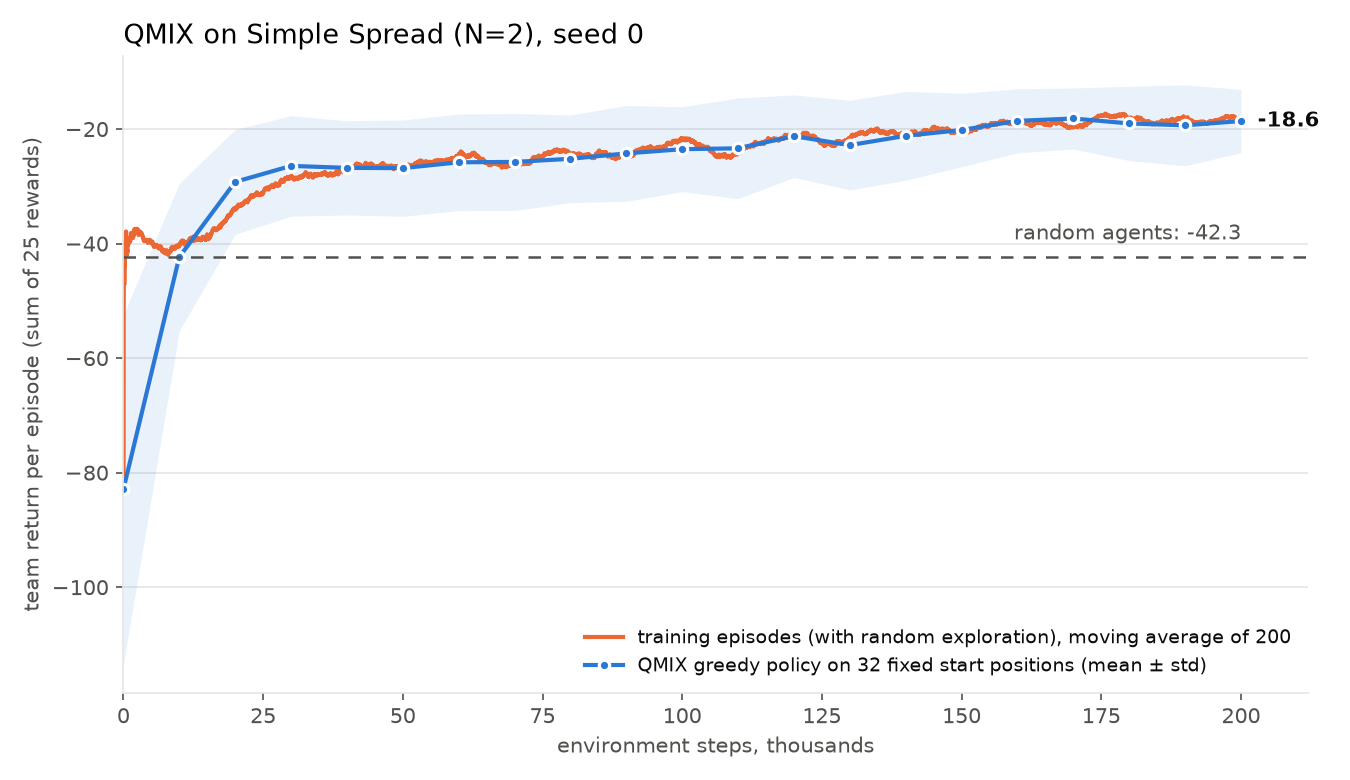

In [16]:
OUTPUT_ROOT = REPO_DIR if not QUICK_CHECK else os.path.join(REPO_DIR, "quick_check")
random_returns = random_baseline(config, config.eval_seeds())  # same 32 start positions, random actions
paths = save_run(result, config, random_returns, OUTPUT_ROOT)
for key, path in paths.items():
    print(f"{key:>10}: {os.path.relpath(path, REPO_DIR)}")
display(Image(filename=str(paths["curve"])))

Return $= \sum_{t=1}^{25} r_t$ (closer to 0 is better). Blue: greedy policy on the 32 fixed start positions (± std). Orange: training episodes with exploration. Dashed: random agents on the same 32 starts.

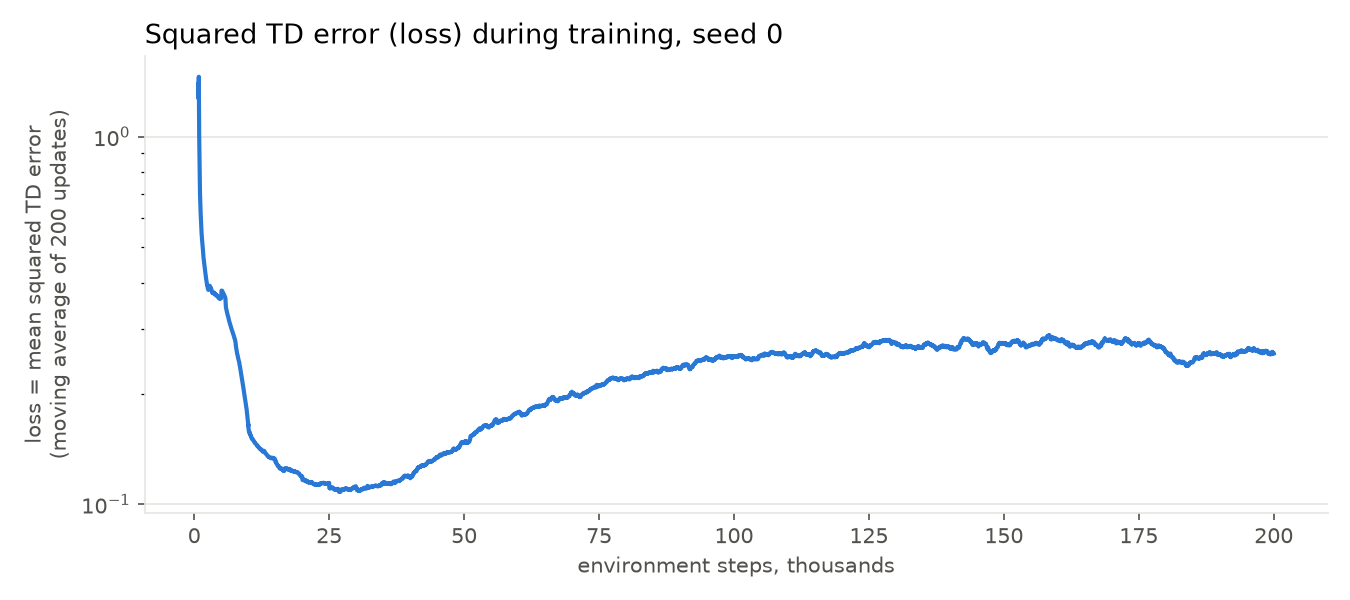

In [17]:
display(Image(filename=str(paths["loss"])))

Loss drops, then settles at ≈ 0.25 while $|Q_{tot}|$ grows from 3 to 12. Divergence would look different: loss growing without bound and $Q_{tot} > 0$ (impossible, all rewards are negative).

## 10. Load the checkpoint and play (no training)

Fresh networks ← weights from file; $\varepsilon = 0$; start position 30 000 was never seen during training.

In [18]:
loaded = load_checkpoint(paths["checkpoint"])
print("loaded:", os.path.relpath(paths["checkpoint"], REPO_DIR))
print("trained for", loaded.metadata["env_steps"], "env steps; created", loaded.metadata["created_utc"], "UTC")

reference = run_episode(env, QMIXPolicy(result.agent_net), seed=30_000)
reference_batch = episodes_to_batch([reference])
with torch.no_grad():
    q_in_memory = unroll_agent_network(result.agent_net, reference_batch["obs"], reference_batch["actions"])
    q_from_file = unroll_agent_network(loaded.agent_net, reference_batch["obs"], reference_batch["actions"])
print("largest difference of Q values, model in memory vs loaded from file:",
      (q_in_memory - q_from_file).abs().max().item())

loaded: models/qmix_spread_n2_seed0.pt
trained for 200000 env steps; created 2026-10-08 11:21:33 UTC
largest difference of Q values, model in memory vs loaded from file: 0.0


  QMIX: return  -10.21 | mean landmark-to-nearest-agent distance at the end 0.104
random: return  -25.49 | mean landmark-to-nearest-agent distance at the end 0.344


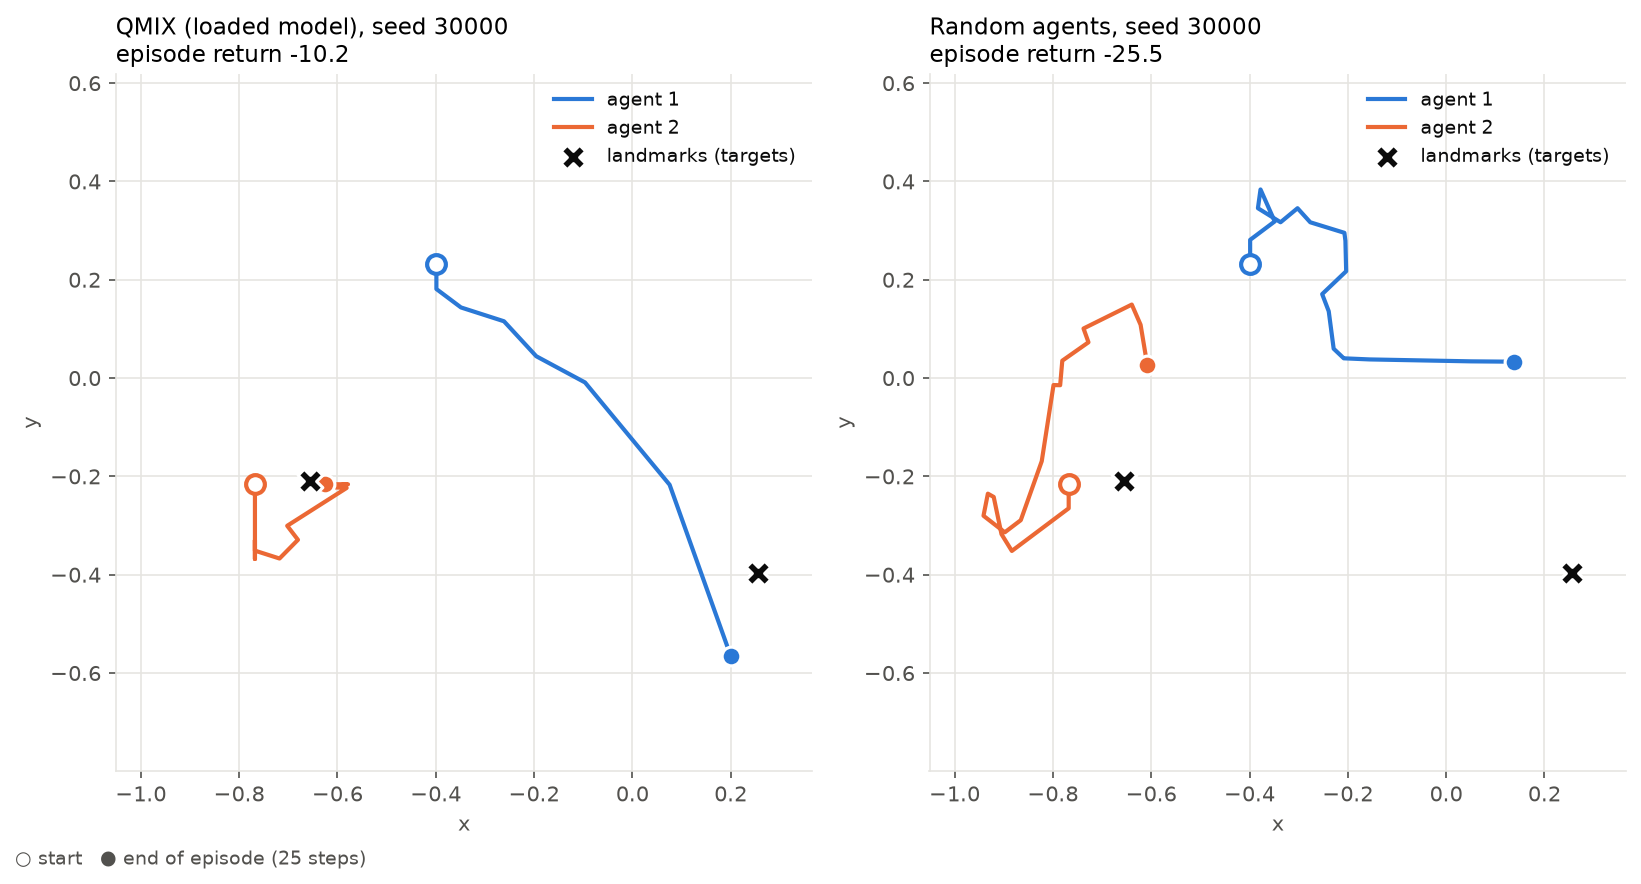

In [19]:
qmix_policy = QMIXPolicy(loaded.agent_net)  # only the agent network: decentralised execution
video_env = SpreadEnv(config, render_mode="rgb_array")  # same dynamics, plus rendered frames
episode = run_episode(video_env, qmix_policy, seed=30_000, record_positions=True, record_frames=True)
random_episode = run_episode(video_env, random_agents, seed=30_000, rng=np.random.default_rng(0),
                             record_positions=True, record_frames=True)
for name, ep in [("QMIX", episode), ("random", random_episode)]:
    print(f"{name:>6}: return {ep.total_reward:7.2f} | mean landmark-to-nearest-agent distance at the end "
          f"{ep.final_mean_distance:.3f}")

trajectory_path = os.path.join(OUTPUT_ROOT, "results", "plots", "qmix_vs_random_episode_seed30000.png")
plot_episode_trajectories([(episode, "QMIX (loaded model), seed 30000"), (random_episode, "Random agents, seed 30000")],
                          trajectory_path);


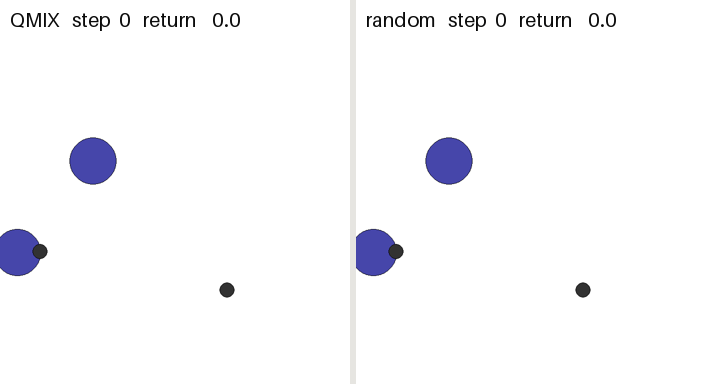

In [20]:
import base64

from IPython.display import HTML

gif_path = save_episode_gif([(episode, "QMIX"), (random_episode, "random")],
                            os.path.join(OUTPUT_ROOT, "media", "demo", "qmix_vs_random_seed30000.gif"))
# As an <img> tag, so the animation also shows on GitHub (it does not render image/gif outputs).
display(HTML(f'<img src="data:image/gif;base64,{base64.b64encode(gif_path.read_bytes()).decode()}">'))

**Held-out check:** 100 new start positions (30 000–30 099), both policies on the same starts. (Official evaluation — Aslan.)

QMIX:   mean -17.17, std 6.45
random: mean -41.00, std 13.34
QMIX better on 100% of the start positions
mean difference 23.83 = 22.4 standard errors (criterion: > 5)


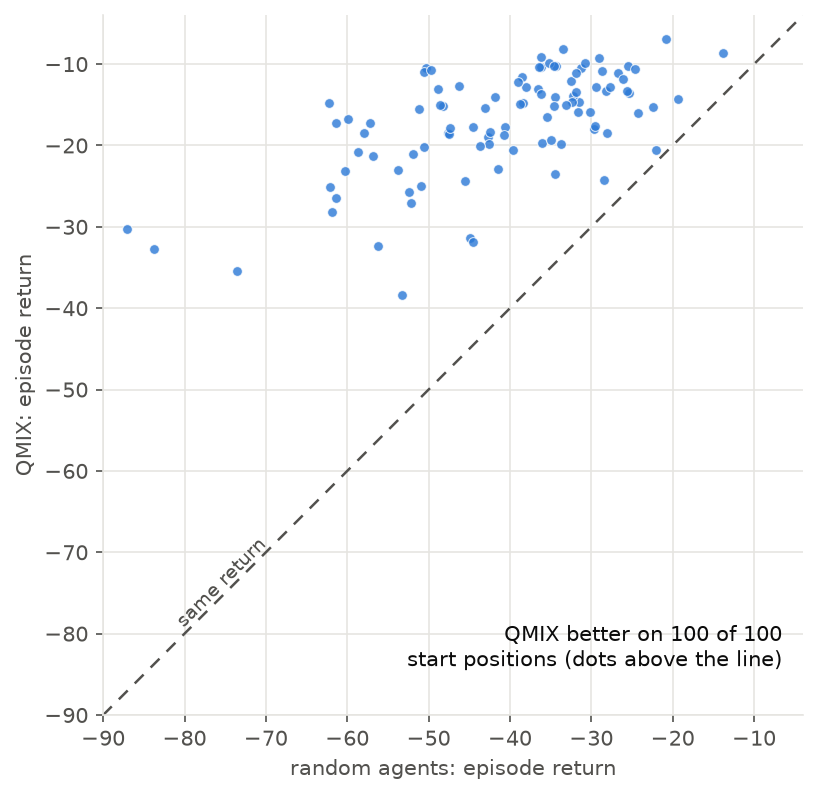

In [21]:
check_seeds = list(range(30_000, 30_100))
qmix_check = evaluate(env, qmix_policy, check_seeds)
random_check = evaluate(env, random_agents, check_seeds, rng=np.random.default_rng(0))
difference = qmix_check - random_check  # paired: same start positions
standard_error = difference.std(ddof=1) / np.sqrt(len(difference))
print(f"QMIX:   mean {qmix_check.mean():.2f}, std {qmix_check.std():.2f}")
print(f"random: mean {random_check.mean():.2f}, std {random_check.std():.2f}")
print(f"QMIX better on {np.mean(difference > 0) * 100:.0f}% of the start positions")
print(f"mean difference {difference.mean():.2f} = {difference.mean() / standard_error:.1f} standard errors (criterion: > 5)")
plot_paired_returns(qmix_check, random_check);

## 11. The same TD step on a real transition

Step 6 of the episode above, through the training code `QMIXLearner.compute_td_loss`; then one gradient step on a copy of the model.

In [22]:
real = real_transition_example(loaded.agent_net, loaded.mixer, loaded.config, episode, step=5, lr=1e-4)
display(Markdown(format_real_example(real, ACTION_NAMES)))

Step 6 of the episode (index 5 in code): agent 1 `move_down`, agent 2 `move_right`

$$
\begin{aligned}
Q_1(\tau_1, \cdot) &= \big(-0.907,\ -1.046,\ -0.878,\ \mathbf{-0.797},\ -1.178\big)\quad \text{(taken action in bold)} \\
Q_2(\tau_2, \cdot) &= \big(-1.209,\ -1.318,\ \mathbf{-1.151},\ -1.268,\ -1.211\big) \\
Q_{tot}(\boldsymbol{\tau}, \mathbf{a}, s) &= g\big(-0.797,\ -1.151;\ s\big) = -3.8678 \\
Q^{-}_{tot}(\boldsymbol{\tau}', \hat{\mathbf{a}}', s') &= g^{-}\big(-0.757,\ -1.159;\ s'\big) = -3.9505 \\
y &= r + \gamma\, Q^{-}_{tot} = -0.7058 + 0.95 \cdot (-3.9505) = -4.4588 \\
\delta &= y - Q_{tot} = -0.591, \qquad \mathcal{L} = \delta^2 = 0.349297 \\
\text{one gradient step } (\eta = 0.0001):\quad Q_{tot} &\to -3.9874, \qquad \delta \to -0.4714
\end{aligned}
$$

Trained model, same step: $Q_{tot}$ of all 25 joint actions, and $\partial Q_{tot} / \partial Q_i \ge 0$ on 1 040 real states.

best joint action: ['move_down', 'move_right'] | each agent's own best: ['move_down', 'move_right']


trained mixer: smallest dQ_tot/dQ_i over 1040 real states: 1.13e-04  (>= 0)


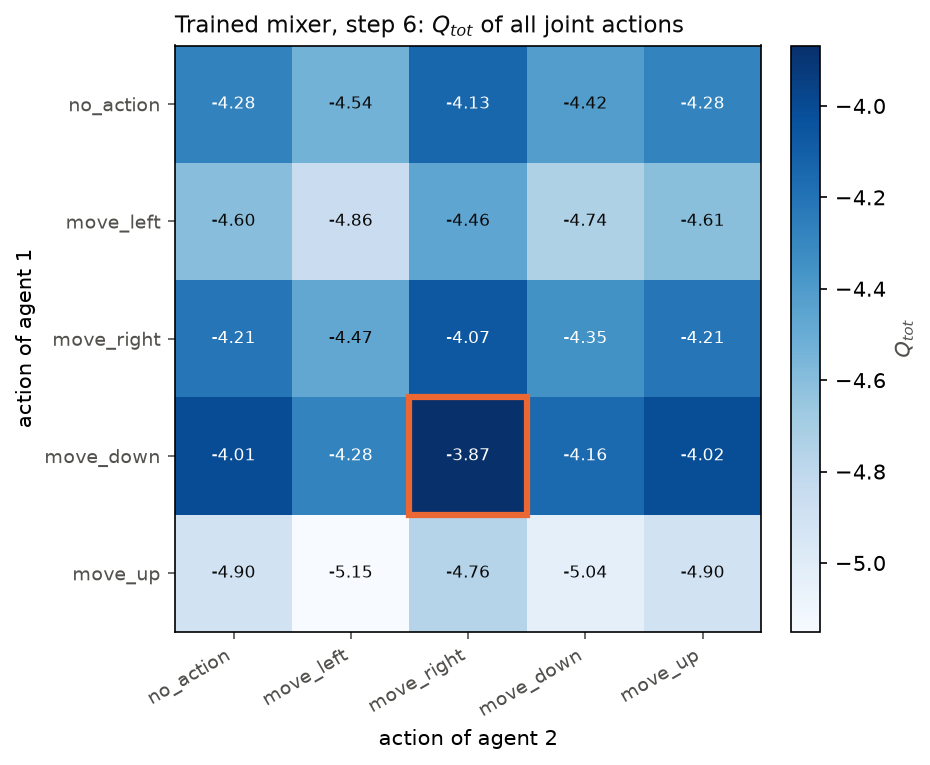

In [23]:
batch_5 = episodes_to_batch([episode])
with torch.no_grad():
    q_trained = unroll_agent_network(loaded.agent_net, batch_5["obs"], batch_5["actions"])[0, 5]  # [n, A] at step 5
state_5 = torch.as_tensor(episode.states[5]).unsqueeze(0)
table = joint_action_q(q_trained, loaded.mixer, state_5)
best_joint = np.unravel_index(table.argmax(), table.shape)
plot_joint_action_q(table, ACTION_NAMES, "Trained mixer, step 6: $Q_{tot}$ of all joint actions");
print("best joint action:", [ACTION_NAMES[a] for a in best_joint],
      "| each agent's own best:", [ACTION_NAMES[int(a)] for a in q_trained.argmax(dim=1)])

# Monotonicity of the trained mixer at real states: dQ_tot/dQ_i >= 0 for random agent values.
seen_states = torch.as_tensor(np.concatenate([run_episode(env, qmix_policy, seed=s).states for s in check_seeds[:40]]))
random_qs = (torch.randn(len(seen_states), env.n_agents) * 20).requires_grad_(True)
(grad,) = torch.autograd.grad(loaded.mixer(random_qs, seen_states).sum(), random_qs)
print(f"trained mixer: smallest dQ_tot/dQ_i over {len(seen_states)} real states: {grad.min():.2e}  (>= 0)")

## 12. Hand-off

| to | what |
| --- | --- |
| Aslan | `models/qmix_spread_n2_seed0.pt` + run code in `models/README.md` |
| Danya | this notebook, `results/plots/qmix_spread_n2_seed0_training_curve.png`, `media/demo/qmix_vs_random_seed30000.gif`, formulas of sections 7 and 11 |

All numbers and versions: `results/qmix_training_report.md`. After merging into `main`: `BRANCH = "main"` in section 0 and in the Colab link.
Download everything this run produced as one archive:

In [24]:
import zipfile

archive = os.path.join(OUTPUT_ROOT, "qmix_outputs.zip")
with zipfile.ZipFile(archive, "w") as zf:
    for path in [*paths.values(), paths["checkpoint"].with_suffix(".json"), trajectory_path, gif_path]:
        zf.write(path, os.path.relpath(path, OUTPUT_ROOT))
print("archive:", os.path.relpath(archive, REPO_DIR))
try:
    from google.colab import files  # only exists in Colab

    files.download(archive)
except ImportError:
    print("not running in Colab: the files are already in the repository folders")

archive: qmix_outputs.zip
not running in Colab: the files are already in the repository folders
